# 실습과제 3 · 시계열 — 지하수위는 비 온 뒤 며칠 만에 오르나 (11주차 · 2026. 11. 16.)

기초지질데이터과학 · **제출: 오늘 23:59, LMS 실습과제 3 — 이 노트북(.ipynb) 하나, 각자 제출** · 5점 = 코드 2 · 해석 2 · 기록지 1

**이름 · 학번:**　202001192  김태연　　　　　　　**쓴 AI:**  chatgpt

**자료** (둘 다 교육용 합성 자료 — 실제 관측 자료의 흔한 문제를 그대로 넣었습니다)
- `groundwater_hourly.csv` — 충적층 관측정 1곳, 2025년, **1시간 간격** 자동 로거. 열: `시각`(한국 시각), `수위_m`(표고, **클수록 지하수면이 높다**).
  현장 기록: 7월 초–중순 통신 장애 · 11/4 오전 로거 교체(새 로거의 기준 높이가 다를 수 있음) · 자료는 두 번에 나눠 내려받아 이어 붙였음.
- `rain_daily.csv` — 같은 유역의 강수 관측소, 2025년 **일강수량**. 기상청 자료와 같은 방식으로 **비가 오지 않은 날은 빈칸**.

**순서**: ① 원자료 점검(1번 칸) → ② 아래 프롬프트를 **그대로** AI에게 보내고(CSV 두 개 첨부) 답과 코드를 기록 → ③ 3번 칸의 도구로 AI의 처리를 **검증**하고, 틀린 곳을 고친 **내 최종 일 수위 `my_daily`**를 만든다 → ④ 해석 · 기록지.


## 0. 도구 — 실행만 하세요 (Shift + Enter)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")
GW_FILE, RAIN_FILE = "groundwater_hourly.csv", "rain_daily.csv"

def load_raw():
    """원자료 두 개를 손대지 않고 읽는다."""
    return pd.read_csv(GW_FILE), pd.read_csv(RAIN_FILE)

def check_time(df, tcol, step):
    """시간 축 점검 — 순서 · 같은 시각 · 빠진 시각(행 자체가 없음) · 빈칸(값 없음). step: '1h' 또는 '1D'."""
    t = pd.to_datetime(df[tcol])
    print(f"행 {len(df):,} · 기간 {t.min()} ~ {t.max()}")
    print("시간 순서대로인가:", t.is_monotonic_increasing)
    print("같은 시각이 다시 나온 행:", int(t.duplicated().sum()))
    missing = pd.date_range(t.min(), t.max(), freq=step).difference(t)
    print("빠진 시각(행이 없음):", len(missing))
    if len(missing):
        m = missing.to_series()
        for _, g in m.groupby((m.diff() != pd.Timedelta(step)).cumsum()):
            print(f"   {g.iloc[0]} ~ {g.iloc[-1]}  ({len(g)}개)")
    print("빈칸(값 없음):", df.drop(columns=[tcol]).isna().sum().to_dict())

def as_hourly(gw):
    """원자료 → 시각 순 Series(같은 시각은 처음 값만). 빠진 시각은 빠진 채로 둔다."""
    s = gw.copy(); s["시각"] = pd.to_datetime(s["시각"])
    return s.drop_duplicates("시각").set_index("시각").sort_index()["수위_m"]

def jump_report(gw, limit=0.15):
    """이웃한 두 관측의 차이가 limit(m)보다 큰 곳. 스파이크는 올라갔다 곧 돌아오고, 단차는 그대로 남는다."""
    s = as_hourly(gw).dropna(); d = s.diff()
    rows = []
    for t in d.index[d.abs() > limit]:
        i = s.index.get_loc(t); t0 = s.index[i - 1]
        rows.append((t0, t, t - t0, s.iloc[i - 1], s.iloc[i], round(d[t], 3)))
    return pd.DataFrame(rows, columns=["앞 시각", "뒤 시각", "간격", "앞 값", "뒤 값", "변화(m)"])

def rain_series():
    """일강수량 Series — 빈칸은 비가 없었던 날이므로 0."""
    _, r = load_raw(); r["일시"] = pd.to_datetime(r["일시"])
    return r.set_index("일시")["일강수량(mm)"].fillna(0.0)

def rain_before(dates, days=7):
    """날짜마다 그날을 포함한 앞 (days+1)일의 강수 합 — 높은 수위가 비 때문인지 확인."""
    r = rain_series(); out = []
    for d in pd.to_datetime(pd.Index(dates)).normalize().unique():
        out.append((d.date(), round(r[d - pd.Timedelta(days=days): d].sum(), 1)))
    return pd.DataFrame(out, columns=["날짜", f"그날까지 {days + 1}일 강수(mm)"])

def before_after(s_hourly, when, hours=72):
    """when 앞뒤 hours시간의 중앙값 비교 — 로거 교체 같은 단차의 크기."""
    t = pd.Timestamp(when); s = s_hourly.sort_index()
    b = s[t - pd.Timedelta(hours=hours): t - pd.Timedelta(hours=1)].median()
    a = s[t: t + pd.Timedelta(hours=hours)].median()
    print(f"{when} 앞 {hours}시간 중앙값 {b:.3f} m · 뒤 {hours}시간 중앙값 {a:.3f} m · 차이 {a - b:+.3f} m")
    return round(a - b, 3)

def xcorr(level_daily, maxlag=10, plot=True):
    """강수(빈칸=0)와 일 수위의 교차상관 — '수위'와 '수위 변화량(오늘−어제)' 두 가지. 날짜로 맞추고 빈 날은 뺀다."""
    r = rain_series(); L = level_daily
    if isinstance(L, pd.DataFrame): L = L.select_dtypes("number").iloc[:, 0]
    L = L.copy(); L.index = pd.to_datetime(L.index); L = L[~L.index.duplicated()].sort_index().asfreq("D")
    cols = {}
    for name, y in [("수위", L), ("수위 변화량", L.diff())]:
        rs = []
        for k in range(maxlag + 1):
            yk = y.shift(-k).reindex(r.index); ok = yk.notna()
            rs.append(np.corrcoef(r[ok], yk[ok])[0, 1] if ok.sum() > 10 else np.nan)
        cols[name] = rs
    tab = pd.DataFrame(cols); tab.index.name = "시차(일)"
    if plot:
        ax = tab.rename(columns={"수위": "level", "수위 변화량": "daily change"}).plot(marker="o", figsize=(6, 3.2))
        ax.set_xlabel("lag (days): rain today -> level k days later"); ax.set_ylabel("correlation"); ax.grid(alpha=.3); plt.show()
    for c in tab: print(f"{c}: 상관이 가장 큰 시차 = {int(tab[c].idxmax())}일 (r = {tab[c].max():.2f})")
    return tab.round(3)

print("도구 준비 완료")


도구 준비 완료


## 1. 원자료 첫 점검 (모두, 5분)

무엇이 이상한지 먼저 보고, AI가 그것을 어떻게 다루는지 지켜봅니다.

=== groundwater_hourly.csv ===
행 8,518 · 기간 2025-01-01 00:00:00 ~ 2025-12-31 23:00:00
시간 순서대로인가: False
같은 시각이 다시 나온 행: 48
빠진 시각(행이 없음): 290
   2025-07-07 00:00:00 ~ 2025-07-18 23:00:00  (288개)
   2025-11-04 08:00:00 ~ 2025-11-04 09:00:00  (2개)
빈칸(값 없음): {'수위_m': 30}

=== rain_daily.csv ===
행 365 · 기간 2025-01-01 00:00:00 ~ 2025-12-31 00:00:00
시간 순서대로인가: True
같은 시각이 다시 나온 행: 0
빠진 시각(행이 없음): 0
빈칸(값 없음): {'일강수량(mm)': 252}


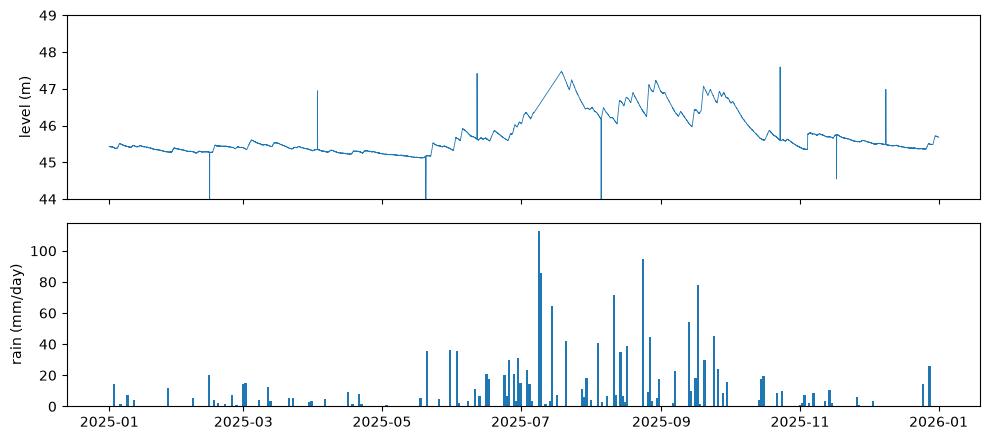

In [2]:
gw, rain = load_raw()
print("=== groundwater_hourly.csv ==="); check_time(gw, "시각", "1h")
print("\n=== rain_daily.csv ==="); check_time(rain, "일시", "1D")
s = as_hourly(gw)
fig, ax = plt.subplots(2, 1, figsize=(10, 4.5), sharex=True)
ax[0].plot(s.index, s.values, lw=.6); ax[0].set_ylabel("level (m)"); ax[0].set_ylim(44, 49)
r = rain_series(); ax[1].bar(r.index, r.values, width=1); ax[1].set_ylabel("rain (mm/day)")
plt.tight_layout(); plt.show()


## 2. AI에게 묻기 (10분)

아래 프롬프트를 **그대로** 보내고 CSV 두 개를 첨부하세요(첨부가 안 되면 내용을 붙여 넣기). 후속 질문은 자유지만, 처음 답은 꼭 기록합니다.

> 첨부한 지하수위 자료(groundwater_hourly.csv, 1시간 간격)와 강수 자료(rain_daily.csv)를 분석하는 파이썬 코드를 짜 줘. 지하수위를 하루 단위로 정리하면서 결측값과 이상값을 처리하고, 비가 온 뒤 며칠 만에 지하수위가 반응하는지 교차상관으로 구해 줘.

**AI의 답 기록** (아래를 채우세요)
- 빠진 시각 · 빈칸을 어떻게 처리했나: 1시간 간격으로 재색인해 빠진 시각을 NaN으로 만들고, 수위의 빈칸과 제거한 스파이크를 시간 보간했다(`limit=2`, `limit_area="inside"`). 다만 이 설정은 긴 결측도 앞쪽 최대 2시간을 채우므로 7월의 장기 공백 전체가 그대로 보존되지는 않고, 나머지는 NaN으로 남는다. 보간·보정 후 하루 유효값이 18개 이상인 날만 일평균을 채택했다.
- 중복된 시각은: 중복 48개를 같은 시각별 수위 중앙값으로 합친 뒤 시간순으로 정렬했다.
- 이상값은 무엇으로 찾았고(기준), 몇 개를 지웠나: 해당 시각과 앞뒤 1시간 값이 모두 존재할 때, 해당 값이 양쪽 이웃 평균에서 0.15 m를 초과해 벗어나고 양쪽 이웃의 차이는 0.05 m 미만인 단일 스파이크를 찾았다. 실행 결과 8개를 NaN으로 바꾼 뒤 보간했다.
- 11/4 로거 교체는 다뤘나: 다뤘다. 2025-11-04 10:00을 기준으로 전·후 각각 72시간의 중앙값 차이(+0.414 m)를 구해 교체 시각 이후 수위에서 뺐다.
- 강수의 빈칸은 어떻게 처리했나: 비가 오지 않은 날로 보고 0.0 mm로 채웠다. 같은 날짜는 합산하고, 일 단위 재색인으로 생긴 빠진 날짜도 0.0 mm로 채웠다.
- 반응 지연(교차상관 최대 시차)은 며칠이라고 했나: 오늘 강수량과 k일 뒤 일평균 수위 변화량(당일−전일)의 피어슨 상관을 0~10일 시차에서 비교한 결과, 최대 시차는 2일(r=0.893)이었다. 결측인 쌍은 제외했다.


중복 시각: 48개
제거한 단일 스파이크: 8개 -> [Timestamp('2025-02-14 03:00:00'), Timestamp('2025-04-02 15:00:00'), Timestamp('2025-05-20 08:00:00'), Timestamp('2025-06-11 21:00:00'), Timestamp('2025-08-05 12:00:00'), Timestamp('2025-10-23 06:00:00'), Timestamp('2025-11-17 02:00:00'), Timestamp('2025-12-08 19:00:00')]
로거 교체 단차 보정량: +0.414 m
최대 교차상관 시차: 2일 (r=0.893)


,상관계수,유효표본수
시차(일),,
0,-0.084,351
1,0.035,351
2,0.893,350
3,-0.002,349
4,-0.148,348
5,0.064,347
6,-0.032,346
7,-0.208,345
8,-0.019,344


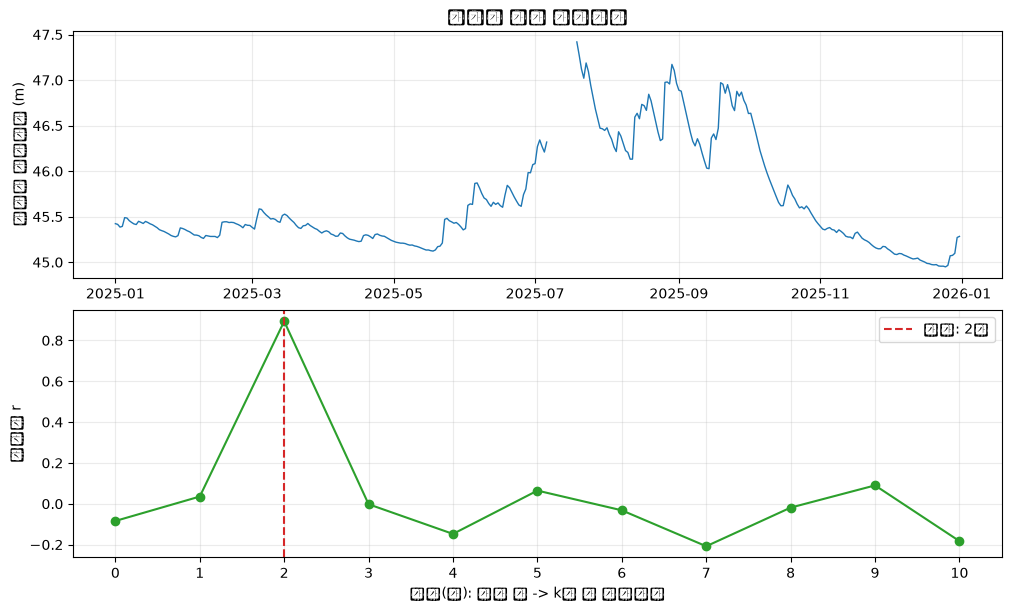

In [3]:
# 1) 원자료 읽기와 시간축 정리
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

gw_ai = pd.read_csv("groundwater_hourly.csv", encoding="utf-8-sig")
rain_ai = pd.read_csv("rain_daily.csv", encoding="utf-8-sig")
gw_ai["시각"] = pd.to_datetime(gw_ai["시각"])
gw_ai["수위_m"] = pd.to_numeric(gw_ai["수위_m"], errors="coerce")
rain_ai["일시"] = pd.to_datetime(rain_ai["일시"])
rain_ai["일강수량(mm)"] = pd.to_numeric(rain_ai["일강수량(mm)"], errors="coerce").fillna(0.0)

# 두 번 다운로드해 생긴 같은 시각은 중앙값으로 하나로 합친 뒤 1시간 격자로 맞춘다.
hourly = gw_ai.groupby("시각")["수위_m"].median().sort_index()
full_hours = pd.date_range(hourly.index.min(), hourly.index.max(), freq="h", name="시각")
hourly = hourly.reindex(full_hours)

# 2) 이상값: 양쪽 이웃은 비슷하지만 해당 한 시간만 0.15 m 이상 튀는 스파이크만 제거
prev_, next_ = hourly.shift(1), hourly.shift(-1)
spike = (hourly.notna() & prev_.notna() & next_.notna()
         & (hourly - (prev_ + next_) / 2).abs().gt(0.15)
         & (prev_ - next_).abs().lt(0.05))
spike_times = hourly.index[spike]
hourly_clean = hourly.mask(spike)

# 스파이크와 1~2시간짜리 짧은 결측만 시간 보간; 7월의 장기 공백은 NaN으로 보존
hourly_clean = hourly_clean.interpolate(method="time", limit=2, limit_area="inside")

# 3) 11/4 10:00 로거 교체 단차: 전·후 72시간 중앙값 차이를 교체 이후 자료에서 뺀다.
change_time = pd.Timestamp("2025-11-04 10:00")
before = hourly_clean.loc[change_time - pd.Timedelta(hours=72): change_time - pd.Timedelta(hours=1)].median()
after = hourly_clean.loc[change_time: change_time + pd.Timedelta(hours=71)].median()
logger_offset = after - before
hourly_clean.loc[change_time:] = hourly_clean.loc[change_time:] - logger_offset

# 4) 일별 평균: 하루 24개 중 18개(75%) 이상일 때만 채택
daily_count = hourly_clean.resample("D").count()
groundwater_daily = hourly_clean.resample("D").mean().where(daily_count >= 18)
groundwater_daily.name = "지하수위_m"
rain_daily = rain_ai.groupby("일시")["일강수량(mm)"].sum().sort_index().asfreq("D", fill_value=0.0)

# 5) 교차상관: 오늘 강수량과 k일 뒤 수위 변화량(오늘-어제)을 비교
analysis_ai = pd.concat([rain_daily, groundwater_daily], axis=1)
analysis_ai["수위변화_m"] = analysis_ai["지하수위_m"].diff()
lag_rows = []
for lag in range(11):
    response = analysis_ai["수위변화_m"].shift(-lag)
    valid = analysis_ai["일강수량(mm)"].notna() & response.notna()
    corr = analysis_ai.loc[valid, "일강수량(mm)"].corr(response[valid])
    lag_rows.append((lag, corr, int(valid.sum())))
lag_corr_ai = pd.DataFrame(lag_rows, columns=["시차(일)", "상관계수", "유효표본수"]).set_index("시차(일)")
best_lag_ai = int(lag_corr_ai["상관계수"].idxmax())

ai_removed_dates = sorted({t.strftime("%Y-%m-%d") for t in spike_times})
print(f"중복 시각: {gw_ai['시각'].duplicated().sum()}개")
print(f"제거한 단일 스파이크: {len(spike_times)}개 -> {list(spike_times)}")
print(f"로거 교체 단차 보정량: {logger_offset:+.3f} m")
print(f"최대 교차상관 시차: {best_lag_ai}일 (r={lag_corr_ai.loc[best_lag_ai, '상관계수']:.3f})")
display(lag_corr_ai.round(3))

fig, axes = plt.subplots(2, 1, figsize=(10, 6), constrained_layout=True)
axes[0].plot(groundwater_daily.index, groundwater_daily, color="tab:blue", lw=1)
axes[0].set(ylabel="일평균 지하수위 (m)", title="정제한 일별 지하수위")
axes[0].grid(alpha=.25)
axes[1].plot(lag_corr_ai.index, lag_corr_ai["상관계수"], marker="o", color="tab:green")
axes[1].axvline(best_lag_ai, color="tab:red", ls="--", label=f"최대: {best_lag_ai}일")
axes[1].set(xlabel="시차(일): 오늘 비 -> k일 뒤 수위변화", ylabel="피어슨 r", xticks=range(11))
axes[1].grid(alpha=.25); axes[1].legend()
plt.show()


## 3. 같은 기준에서 검증 (25분) — 칸마다 실행하고, AI의 처리와 비교하세요

In [4]:
# 3-1. 시간 축 — 7/7–7/18(행이 없는 12일) 동안 비가 얼마나 왔나? 이 구간을 직선으로 이어도 될까?
r = rain_series()
print("7/7–7/18 강수 합:", r["2025-07-07":"2025-07-18"].sum(), "mm")
print(r["2025-07-07":"2025-07-18"][r["2025-07-07":"2025-07-18"] > 0])
s = as_hourly(gw)
print("\n빠진 구간 바로 앞 · 뒤 수위:", s[:"2025-07-06 23:00"].iloc[-1], "→", s["2025-07-19":].iloc[0], "m")


7/7–7/18 강수 합: 275.5 mm
일시
2025-07-09    112.5
2025-07-10     86.0
2025-07-12      1.8
2025-07-14      3.4
2025-07-15     64.5
2025-07-17      7.3
Name: 일강수량(mm), dtype: float64

빠진 구간 바로 앞 · 뒤 수위: 46.35 → 47.472 m


In [5]:
# 3-2. 이상값 — 원자료에서 '이웃 시각과 0.15 m 넘게 다른 곳'. 스파이크는 쌍(올라감 → 돌아옴)으로, 단차는 하나만 나온다.
jumps = jump_report(gw)
display(jumps)
# AI가 지운 날짜가 실제로는 '큰 비 뒤의 상승'이 아니었는지:
if ai_removed_dates:
    display(rain_before(ai_removed_dates))


,앞 시각,뒤 시각,간격,앞 값,뒤 값,변화(m)
0,2025-02-14 02:00:00,2025-02-14 03:00:00,0 days 01:00:00,45.274,0.000,-45.274
1,2025-02-14 03:00:00,2025-02-14 04:00:00,0 days 01:00:00,0.000,45.266,45.266
2,2025-04-02 14:00:00,2025-04-02 15:00:00,0 days 01:00:00,45.347,46.945,1.598
3,2025-04-02 15:00:00,2025-04-02 16:00:00,0 days 01:00:00,46.945,45.339,-1.606
4,2025-05-20 07:00:00,2025-05-20 08:00:00,0 days 01:00:00,45.167,43.774,-1.393
5,2025-05-20 08:00:00,2025-05-20 09:00:00,0 days 01:00:00,43.774,45.170,1.396
6,2025-06-11 20:00:00,2025-06-11 21:00:00,0 days 01:00:00,45.628,47.420,1.792
7,2025-06-11 21:00:00,2025-06-11 22:00:00,0 days 01:00:00,47.420,45.625,-1.795
8,2025-07-06 23:00:00,2025-07-19 00:00:00,12 days 01:00:00,46.350,47.472,1.122
9,2025-08-05 11:00:00,2025-08-05 12:00:00,0 days 01:00:00,46.162,0.000,-46.162


,날짜,그날까지 8일 강수(mm)
0,2025-02-14,25.4
1,2025-04-02,6.2
2,2025-05-20,5.2
3,2025-06-11,16.7
4,2025-08-05,69.2
5,2025-10-23,28.1
6,2025-11-17,15.5
7,2025-12-08,3.6


In [6]:
# 3-3. 11/4 로거 교체 — 앞뒤 3일 중앙값 비교. 비는 왔나?
step = before_after(as_hourly(gw), "2025-11-04 10:00")
print("11/1–11/7 강수:", rain_series()["2025-11-01":"2025-11-07"].sum(), "mm")


2025-11-04 10:00 앞 72시간 중앙값 45.360 m · 뒤 72시간 중앙값 45.774 m · 차이 +0.414 m
11/1–11/7 강수: 21.700000000000003 mm


제거한 스파이크: 8개 / 단차 보정량: +0.414 m
보간한 시간: 40개 / 유효 일평균: 353일
7/7–7/18 장기 공백 유지: True


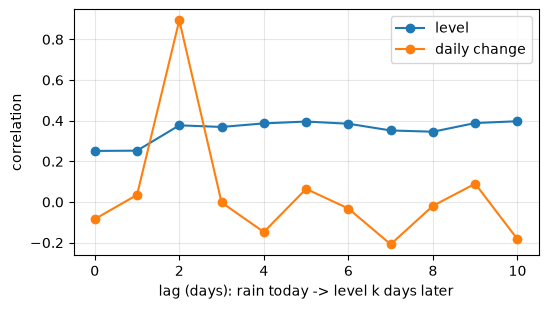

수위: 상관이 가장 큰 시차 = 10일 (r = 0.40)
수위 변화량: 상관이 가장 큰 시차 = 2일 (r = 0.89)


,수위,수위 변화량
시차(일),,
0,0.251,-0.084
1,0.252,0.035
2,0.377,0.894
3,0.369,-0.002
4,0.387,-0.148
5,0.396,0.064
6,0.385,-0.032
7,0.352,-0.208
8,0.346,-0.019


In [7]:
# 3-4. 검증을 반영한 최종 일 수위
# 같은 시각은 중앙값으로 합치고, 시간 격자에 없는 관측은 NaN으로 둔다.
gw_final, _ = load_raw()
gw_final["시각"] = pd.to_datetime(gw_final["시각"])
h = gw_final.groupby("시각")["수위_m"].median().sort_index().asfreq("h")

# 양쪽 이웃은 비슷한데 한 시간만 튀는 로거 오류 8개를 제거한다.
left, right = h.shift(1), h.shift(-1)
spikes = (h.notna() & left.notna() & right.notna()
          & (h - (left + right) / 2).abs().gt(0.15)
          & (left - right).abs().lt(0.05))
h = h.mask(spikes)

# 로거의 기준 높이 차이를 먼저 보정한다. 보정 전 단차를 가로질러 보간하지 않는다.
changed = pd.Timestamp("2025-11-04 10:00")
b = h.loc[changed - pd.Timedelta(hours=72): changed - pd.Timedelta(hours=1)].median()
a = h.loc[changed: changed + pd.Timedelta(hours=71)].median()
offset = a - b
h.loc[changed:] = h.loc[changed:] - offset

# 연속 결측 구간 전체가 2시간 이하인 경우에만 내부 보간한다.
# interpolate(limit=2)만 쓰면 긴 공백의 첫 2시간도 채워지는 문제를 수정했다.
missing = h.isna()
run_id = missing.ne(missing.shift()).cumsum()
run_length = missing.groupby(run_id).transform("sum")
short_gap = missing & run_length.le(2)
interpolated = h.interpolate(method="time", limit_area="inside")
h = h.mask(short_gap, interpolated)

# 하루 24시간 중 유효값이 18개 이상인 날만 일평균으로 채택한다.
valid_hours = h.resample("D").count()
my_daily = h.resample("D").mean().where(valid_hours >= 18)
my_daily.name = "지하수위_m"

print(f"제거한 스파이크: {spikes.sum()}개 / 단차 보정량: {offset:+.3f} m")
print(f"보간한 시간: {(missing & h.notna()).sum()}개 / 유효 일평균: {my_daily.notna().sum()}일")
print("7/7–7/18 장기 공백 유지:", h.loc["2025-07-07":"2025-07-18"].isna().all())
tab = xcorr(my_daily)
display(tab)


## 4. 해석 (해석 2점) — 수치와 근거를 넣어 짧게

**Q1. 시간 축.** 원자료의 문제(같은 시각 몇 행, 빠진 시각 언제 몇 개, 빈칸 몇 개)와 AI가 각각을 어떻게 처리했는지. 7/7–7/18을 직선으로 이어도 되나? (근거: 그 기간 강수)

지하수위 원자료는 시간순으로 정렬되어 있지 않고, 중복 시각이 48행 있다. 행 자체가 빠진 시각은 7/7 00:00~7/18 23:00의 288시간과 11/4 08:00~09:00의 2시간으로 총 290개이며, 존재하는 행의 수위 빈칸은 30개다. AI는 중복을 시각별 중앙값으로 합치고 정렬한 뒤, 1시간 격자로 재색인해 빠진 시각을 NaN으로 만들었다. 다만 `interpolate(limit=2)`는 긴 결측의 첫 2시간도 채우므로, 최종 코드에서는 연속 결측 구간 전체가 2시간 이하일 때만 보간하도록 고쳤다. 7/7~7/18에는 총 275.5 mm의 비가 왔고 공백 앞뒤 수위는 46.350→47.472 m다. 그 사이 상승·하강 과정을 알 수 없으므로 직선 보간은 근거가 부족하며, 12일 전체를 결측으로 남겼다. 강수 자료는 중복·빠진 날짜가 없고 빈칸 252개는 자료 설명에 따라 무강수인 0 mm로 처리했다.

**Q2. 이상값.** AI가 이상값으로 지운 것 중 **실제 지하수위 변화**(큰 비 뒤 상승)였던 것과, AI가 **놓친 로거 오류**는? (근거: 3-2 표, 강수)

이번 AI 코드가 제거한 것은 2/14, 4/2, 5/20, 6/11, 8/5, 10/23, 11/17, 12/8의 단일 스파이크 8개다. 3-2 표에서는 모두 급변한 바로 다음 시간에 원래 수준으로 돌아오는 쌍으로 나타나므로, 확인한 범위에서 실제 강수 반응을 잘못 지운 사례나 놓친 단일 스파이크는 없다. 예를 들어 8/5까지 8일 강수는 69.2 mm이지만 수위가 46.162→0→46.187 m로 한 시간만 0이 되는 것은 로거 오류로 판단했다. 반면 7/19의 +1.122 m 변화는 12일 1시간의 관측 공백을 사이에 둔 차이이며, 공백 동안 275.5 mm의 비가 왔으므로 순간 스파이크로 제거하면 안 된다. 11/4의 +0.424 m 변화는 교체 후에도 남는 단차로, 한 점을 지우는 대신 이후 자료의 기준 높이를 보정했다.

**Q3. 로거 교체.** 11/4 단차의 크기와 처리 — 지웠나, 보정했나? 왜 그렇게 해야 하나?

11/4 10:00 전후 72시간 중앙값은 약 45.360 m와 45.774 m로 차이는 +0.414 m다. 교체 직전·직후 관측값 차이도 +0.424 m이므로, 최종 코드에서는 교체 이후 모든 수위에서 중앙값 차이인 약 0.414 m를 빼서 보정했다. 단차는 이후 관측 전체에 지속되는 기준 높이의 차이이므로 교체 순간의 값만 삭제해서는 해결되지 않는다. 보정 후 짧은 결측을 보간해 서로 다른 기준 높이를 그대로 연결하지 않도록 했다. 다만 11/1~11/7 강수는 21.7 mm로 무강수 기간은 아니므로, 중앙값 차이에 실제 수위 변화도 일부 포함될 수 있다. 따라서 이 값은 현장 교체 기록과 급격한 단차에 근거한 추정 보정량이며, 정확한 기준 높이 차이는 별도 기준 수위 측정으로 확인해야 한다.

**Q4. 반응 지연.** 비가 온 뒤 며칠 만에 수위가 오르기 시작하나? '수위'와 '수위 변화량'의 교차상관 결과가 다르면 왜? 이 지연은 지질학적으로 무엇을 뜻하나?

최종 일 수위는 하루 유효값이 18개 이상인 353일에 대해 계산했다. 0~10일 시차를 비교하면 강수와 수위 변화량의 상관은 **2일에서 최대(r=0.894)**이므로, 이 자료의 대표적인 상승 반응 지연은 약 2일로 해석한다. 이는 모든 강우 사건의 최초 반응 시점을 정확히 확정한 값은 아니다. 수위 자체의 상관은 비교 범위의 끝인 **10일에서 최대(r=0.397)**였다. 수위에는 이전 강수의 누적 효과와 느린 배수·계절 변동이 남지만, 일별 변화량은 상승 시점에 더 민감하기 때문에 결과가 다를 수 있다. 특히 10일은 탐색 범위의 경계이므로 이를 확정적인 반응 지연으로 해석하지 않는다. 약 2일의 지연은 빗물이 지표와 불포화대를 거쳐 대수층을 함양하고 관측정 수위에 반영되는 과정의 시간 규모를 나타내며, 물 입자 자체의 이동 시간을 직접 측정한 값은 아니다.


## 5. AI 활용 기록지 (기록지 1점 — 2건 이상)

| # | 도구 | 프롬프트(요지) | 산출물(요지) | 검증(무엇으로 확인했나) | 수정(무엇을 고쳤나) |
|---|---|---|---|---|---|
| 1 | chatgpt | 첨부한 자료를 분석하는 코드 요청 | 중복 정리, 스파이크 제거, 보간, 로거 단차 보정 및 교차상관 코드 | 3-1~3-3으로 공백 기간 강수 275.5 mm, 스파이크 8개, 교체 전후 단차 약 0.414 m 확인 | 긴 결측의 첫 2시간도 채우는 보간을, 전체 결측 구간이 2시간 이하일 때만 채우도록 수정 |
| 2 | chatgpt | 검증을 반영한 ai 제시 코드의 수정 요청 | my_daily 생성 코드  | 전체 셀 실행으로 장기 공백 유지, 유효 일평균 353일, 수위 변화량의 최대 상관 시차 2일(r=0.894) 확인  | 단차 보정 후 보간하도록 순서 변경. 교체 전후 강수에 따른 보정의 한계와 수위 자체의 최대 시차 10일이 탐색 범위 끝이라는 점을 해석에 반영  |
